# Mode 2 resource allocation

How a UE picks its sidelink resources in MoReV2X, and what you can change. The logic follows TS 38.214 section 8.1.4 and TS 38.321 section 5.22.1, with the deviations listed in [section 13](#13-where-it-differs-from-3gpp).

All references are to `src/MoReV2X/model/`. Almost all of the scheduler is one class, `NrV2XUeMac`, in `nr-v2x-ue-mac.cc`.

**Measured on ns-3.22.** The figures here come from `develop`. The ns-3.42 port reproduces them within the confidence intervals, see [notebook 06](06_ns3_migration.ipynb). Commands in this notebook use the `ns-3.22` file names where they differ, see `COMMANDS.txt` for this branch.

In [1]:
import os, subprocess, sys
sys.path.insert(0, os.path.abspath("../../tools"))
import morev2x_results as mr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 90)
mr.apply_chart_style()
os.chdir(mr.ROOT)

## 1. The path of a packet

```
UdpClient::Send              scratch/HIGHWAY.cc   builds the packet and an NrV2XTag:
      |                                           PDB, RRI, size, reservation size, Cresel
      v
RLC UM                       nr-v2x-rlc-um.cc     copies the tag into the buffer status report
      |
      v                      every slot
NrV2XUeMac::DoSubframeIndication   ---------------------------------+
      |                                                             |
      |  no valid grant?                                            |
      v                                                             |
V2XSelectResources           the scheduler                          |
      |-- SelectionWindow    builds Sa, every candidate             |
      |-- Mode2Step1         sensing: removes candidates, gives L1  |
      |-- random pick from L1, plus a 2nd one for a re-transmission |
      v                                                             |
grant stored in the pool  <------ ReEvaluateResources T3 before Tx -+
      |
      v
SCI (PSCCH) + TB (PSSCH)     m_uePhySapProvider
      |
      v  other UEs
NrV2XSpectrumPhy             RSRP measured, PSCCH decoded
      |
      v
NrV2XUePhy::ReceiveNistLteControlMessageList
      |
      v
DoReportPsschRsrpReservation stored in m_sensedReservedCSRMap, read by their Mode2Step1
```

There is no scheduler class and no gNB. Every UE runs this alone, from what it decoded.

## 2. The resource grid

A **candidate single-slot resource (CSR)** is one slot and a run of adjacent subchannels.

| Quantity | Source | Default in `HIGHWAY` |
|---|---|---|
| Slot duration | `1/2^mu` ms, `--Numerology` | 1 ms |
| RBs in the channel | `GetRbsFromBW`, `--ChannelBW` | 52 (10 MHz at 15 kHz) |
| Subchannel size | `--SubChannel` | 10 RBs, the AMC refuses less |
| Subchannels `NSubCh` | `floor(RBs / size)` | 5 |
| Subchannels per TB `L_SubCh` | `NrV2XAmc::GetSlSubchAndTbSizeFromMcs` | from MCS and packet size |
| CSRs per slot | `NSubCh - L_SubCh + 1` | 4 for `L_SubCh = 2` |

The AMC walks `L_SubCh = 1, 2, ...` until the TB fits, after removing PSCCH, DMRS, overhead and second-stage SCI REs. PSCCH always sits in the first subchannel of the reservation.

For a 200 byte packet at MCS 13 the TB needs 2 subchannels. So a 100 ms PDB gives slots 2 to 99, 98 slots with 4 CSRs each, and 392 candidates, the value seen in the logs below.

In [2]:
run = mr.simulate("rsrp128", "--Vehicles=120", "--simTime=10", "--mcs=13", "--seed=1", "--Periodic", "--RSRP=-128")
ssps = run.ssps
ssps[["PDB", "RRI", "nCSRinitial", "rbLen"]].value_counts().rename("selections").reset_index()

,PDB,RRI,nCSRinitial,rbLen,selections
0,100,100,392,20,966
1,20,20,72,20,242


## 3. When selection runs

`DoSubframeIndication` (`nr-v2x-ue-mac.cc:2413`) runs every slot. A selection is triggered in three ways, recorded in the `trigger` column of `SSPSlog.txt`:

| Trigger | Value | Condition |
|---|---|---|
| `COUNTER` | 0 | Data is waiting and there is no valid grant (`nr-v2x-ue-mac.cc:2586`) |
| `LATENCY` | 2 | The reserved slot would miss the PDB of this packet (`nr-v2x-ue-mac.cc:2647`) |
| `SIZE` | 3 | The packet needs more RBs than reserved (`nr-v2x-ue-mac.cc:2687`) |
| `LATENCYandSIZE` | 1 | Both |
| `ReEVALUATION` | 4 | A selected resource was found occupied, see section 9 |

Latency and size triggers only occur with aperiodic or variable-size traffic. Periodic traffic only produces counter selections, and an assertion checks it.

## 4. The selection window

`nr-v2x-ue-mac.cc:1851` lists every CSR in `[n + T1, n + T2]`.

```cpp
// V2XSelectResources
double T_2 = pdb - m_slotDuration;
uint32_t T_2_slots = T_2/m_slotDuration;

// SelectionWindow
uint32_t T_1_slots = 2;                        // hardcoded, GetTproc1 is commented out
for (uint16_t j=0; j< N_CSR_per_SF; j++)
  for (uint32_t i = T_1_slots; i <= T_2_slots; i++)
    SFvector.push_back (candidateSF);
```

So **the PDB sets T2**, always at its maximum. There is no separate `T2min` or priority-based window. A short PDB directly reduces the number of candidates: a 20 ms PDB leaves 72 candidates instead of 392.

## 5. Sensing

A UE learns about reservations only from the SCIs it **decoded**. `nr-v2x-ue-phy.cc:1012` passes each one to `nr-v2x-ue-mac.cc:3347`, which stores it by subchannel and reception slot:

```cpp
std::map<uint16_t,                                   // subchannel
         std::map<SubframeInfo,                      // slot it was received in
                  std::vector<ReservedCSR>>> m_sensedReservedCSRMap;  // RSRP, RRI, Cresel, sender
```

- The RSRP is the mean per-RE power of that transmission, **without interference** (`nr-v2x-spectrum-phy.cc:1184`).
- Entries older than the **sensing window**, 1100 ms, are dropped (`m_sensingWindow`, `nr-v2x-ue-mac.cc:530`).
- Entries younger than **T_proc,0** are ignored as too late to process (1 slot at 15 and 30 kHz, 2 at 60 kHz).
- An SCI with `m_reservation = 0` adds nothing. That is a transmission that reserves no next period: the last one of a grant, and every dynamic transmission.

A UE that is transmitting cannot hear, so half-duplex losses also leave gaps in sensing.

## 6. Step 1: excluding candidates

`nr-v2x-ue-mac.cc:1883` takes `Sa` and returns `L1`. It removes candidates in two passes.

**Own past transmissions.** The UE did not hear those slots, so it assumes each of them may repeat at **every RRI in `m_RRIvalues`**, and removes those slots across all subchannels. This list is per MAC and filled by `PushNewRRIValue`.

**Sensed reservations.** For each stored reservation with RSRP above the threshold, the next occurrences are projected and marked:

```cpp
if (resIt->psschRsrpDb >= *psschThresh)
{
  if ((elapsed <= RRI_slots) && (resIt->RRI < T_2) && !(resIt->isReTx))
    Q = std::ceil ((float) T_2 / resIt->RRI);   // short RRI: several repeats fall in the window
  else
    Q = 1;
  for (q = 1; q <= Q; q++)
    L1_out[subchannel].push_back (receivedSlot + q*RRI_slots);
}
```

A candidate is then dropped if **any of its own future periods** hits a marked slot, on any subchannel it would occupy. Both passes check `Cresel` future transmissions, not just the first:

```cpp
for (Cresel = 0; Cresel < V2XGrant.m_Cresel; Cresel++)
{
  futureTxFrame = candidate + Cresel * RRI_slots;
  if (find (L1_out_full[csr].begin (), L1_out_full[csr].end (), futureTxFrame) != end) erase candidate;
}
```

So a longer `Cresel` makes each candidate harder to keep.

**The 20 % rule.** If fewer than `m_sizeThreshold` of the candidates survive, the threshold rises by 3 dB and the pass restarts (`nr-v2x-ue-mac.cc:2253`):

```cpp
while (nCSRresidual < L1targetSize * nCSRtot)   // L1targetSize = 0.2
{
  ...
  nCSRresidual = ComputeResidualCSRs (L1);
  *psschThresh += 3;
  *iterationsCounter += 1;
}
```

The candidate count `nCSRtot` is taken **after** removing own past transmissions. `SSPSlog.txt` logs all of it: `nCSRinitial`, `nCSRpastTx`, `nCSRfinal`, `iterations`, and the final threshold.

If own past transmissions cover the entire window, which happens with a short RRI, the full window is used instead (`nr-v2x-ue-mac.cc:2009`). In upstream that case indexed an empty vector.

The funnel of a real run, for each selection at 120 vehicles on 5 km:

{1: 1003, 3: 23, 4: 21, 5: 42, 6: 60, 7: 38, 8: 16, 9: 5} iterations of the threshold loop


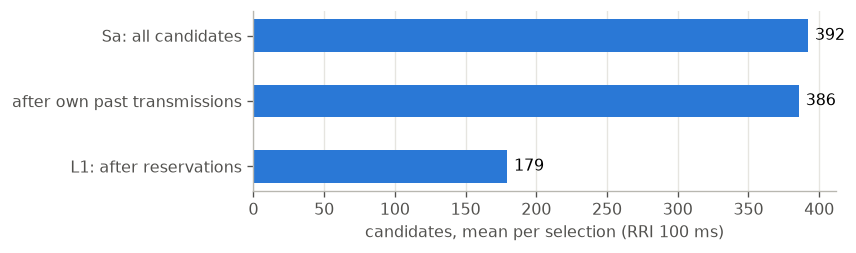

In [3]:
funnel = ssps[ssps.RRI == 100][["nCSRinitial", "nCSRpastTx", "nCSRfinal"]].mean()
fig, ax = plt.subplots(figsize=(7.2, 2.2))
labels = ["Sa: all candidates", "after own past transmissions", "L1: after reservations"]
ax.barh(labels[::-1], funnel.values[::-1], color=mr.SERIES_COLORS[0], height=0.5)
for y, value in enumerate(funnel.values[::-1]):
    ax.text(value + 5, y, f"{value:.0f}", va="center")
ax.set_xlabel("candidates, mean per selection (RRI 100 ms)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
print(ssps.iterations.value_counts().sort_index().to_dict(), "iterations of the threshold loop")

## 7. Step 2: picking a resource

3GPP leaves this choice to the UE. Here it is a uniform draw from `L1` (`nr-v2x-ue-mac.cc:1571`):

```cpp
CandidateCSRl2 FirstSelectedResource = finalL2[selectFromL2 -> GetInteger (0, finalL2.size () - 1)];
```

`finalL2` is `L1` flattened. `rssi` stays 0: the LTE-style ranking by RSSI (`ListL2Enabled`) asserts as unavailable.

**This one line is the place for a custom selection rule.** Replacing the uniform draw with any function of `finalL2` changes the scheduler while keeping sensing intact, which is the cheapest experiment in this code base.

## 8. Blind re-transmissions

With `--ReTx`, a second resource is drawn from `L1` in a different slot, preferably within 32 slots of the first (`nr-v2x-ue-mac.cc:1648`), because SCI can only point that far.

- `UnimoreSortSelections` orders them, handling the SFN wrap. `m_grantTransmissions[1]` is the first in time.
- Inside 32 slots the first SCI announces the second (`m_announceNextTxion`), and receivers store it with `isReTx = 1`.
- The maximum is 2 transmissions per TB (`m_TxNumber`).
- There is no HARQ feedback. Both copies are always sent, and PSFCH is not simulated.

## SPS lifetime

A grant repeats every RRI until `Cresel` reaches 0 (`nr-v2x-utils.cc:180`):

```cpp
if (RRI >= 100)  Cresel = uniform [5, 15];
else             Cresel = uniform [5*C, 15*C];   // C = 100 / max(20, RRI)
```

At expiry the UE keeps the grant with probability `Pkeep` (`--pkeep`), and draws a new `Cresel`. The SCI of the last transmission has `m_reservation = 0`, which is how others know the resource is about to free up.

## 9. Re-evaluation

Selection is made up to 100 ms before the transmission, so a neighbour can claim the same slot in between. Re-evaluation repeats the check shortly before transmitting.

`nr-v2x-ue-mac.cc:3458` runs **T3 = T_proc,1** slots (3 at 15 kHz) before the selected slot:

1. Rebuilds the window with the remaining PDB.
2. Runs `Mode2Step1` again. If the selected CSR is no longer in `L1`, it is marked for change.
3. `nr-v2x-ue-mac.cc:3699` reselects only the affected transmissions, with trigger 4.

| Option | Effect |
|---|---|
| `--ReEvaluation` | Acts on the result |
| `--AllSlots` | Checks in every slot between selection and T3, not only at T3 |
| `--UMH` | Passes `OnlyReTxions = true`, so only reservations that announce a re-transmission of the same TB count |
| none | **The check still runs and is logged**, it just changes nothing (`nr-v2x-ue-mac.cc:2749`). So `ReEvaluationsLog.txt` also tells you what re-evaluation would have done |

There is no pre-emption: a UE never gives up a resource for a higher-priority one, because priority is not modelled.

## 10. The other schedulers

They are all flags on the same function, not separate implementations.

| Flag | What it does |
|---|---|
| `--Dynamic` | Sets `Cresel = 1`. Every packet gets a new selection, nothing is reserved for the next period, and the UE announces nothing |
| `--Mixed --Percentage=N` | N % of UEs send periodic traffic, the others aperiodic |
| `--Adaptive` | With `--Mixed`: SPS for periodic traffic, dynamic for aperiodic |
| `--AdaptiveRRI` | Each UE changes its RRI and `Pkeep` from the load it senses, see below |
| `--FreqReuse --ReuseDist=D` | With `--Dynamic`: the subchannel is chosen by geographic cell along x, ignoring sensing for that choice (`nr-v2x-ue-mac.cc:1576`). The map assumes the straight highway |

Options that exist but stop the run: `RandomV2VSelection`, `OneShot`, `ListL2Enabled`, `useRxCresel`.

### Adaptive reservation

`--AdaptiveRRI`, or `adaptive` per node. Off by default. At each counter reselection, `UpdateAdaptiveReservation` measures the free share of the channel from sensing, over the last `AdaptiveWindow` (100 ms), and calls `NrV2XAdaptiveReservation::Update`:

```cpp
if (freeRatio < freeLow)        { next += rriDelta; keep -= beta; }  // busy: slow down, reselect more
else if (freeRatio > freeHigh)  { next -= rriDelta; keep += beta; }  // free: speed up, hold resources
next = Limit (next);                                                 // rriMin to rriMax, on a 10 ms grid
next = beta * next + (1 - beta) * averageOf (neighbourRris);         // converge with the neighbours
```

Three consequences to keep in mind:

- **It changes the traffic.** The packet period follows the RRI, so this is rate control. A UE on a free channel sends more than its application's base rate, down to one packet every `AdaptiveRriMin`.
- **The free ratio sees only decoded SCIs with a reservation.** Dynamic UEs, and anything out of decoding range, count as free.
- **It replaces `Pkeep`** on that UE: the keep probability starts at 0.5 and moves by `beta`, up to 0.8.

The first packet after an RRI change was already scheduled with the old period, so it can trigger a latency reselection, with `trigger = 2`. The RRI does not change on those.

## 11. Tuning

### From the command line
| Option | Attribute | Effect |
|---|---|---|
| `--RSRP` | `RSRPthreshold` | Starting exclusion threshold (dBm). Lower excludes more, so UEs spread out, at the risk of raising the threshold through the 20 % rule anyway |
| `--mcs` | `SlGrantMcs` | Link robustness against subchannels used per TB. Allowed up to 27 by the AMC, despite the attribute text. **0 silently disables transmission** |
| `--SubChannel`, `--ChannelBW` | `SubchannelSize`, `RBsBandwidth` | Set the number of CSRs. Must match on all UEs |
| `--Numerology` | `NumerologyIndex`, `SlotDuration` | Slot length, so also candidates per ms |
| `--PDB` | packet tag | T2. Must be below 110 ms and not above the RRI |
| `--ReTx` | `EnableReTx` | Second copy, at the cost of twice the channel load |
| `--pkeep` | `Pkeep` | Probability of keeping a grant when `Cresel` expires. Fewer reselections, resources stay taken for longer |
| `--AdaptiveRRI` | `AdaptiveReservation` | RRI and rate follow the sensed load |
| `--ns3::NrV2XUeMac::AdaptiveRriMin=50` | `AdaptiveRriMin`, `AdaptiveRriMax`, `AdaptiveRriDelta`, `AdaptiveFreeLow`, `AdaptiveFreeHigh`, `AdaptiveWindow` | Limits and thresholds of adaptive reservation, in ms and ratios |
| `--ReEvaluation`, `--AllSlots`, `--UMH` | as named | Section 9 |
| `--Dynamic`, `--Adaptive` | as named | Section 10 |
| `--ueTxPower` | `TxPower` | Range and interference together |
| `--SchedulerMap` | any of the above, per node | [Notebook 03](03_per_node_schedulers.ipynb) |

### Only by editing code
These are constants today. Each would be a one-line `AddAttribute`.

| Parameter | Value | Where |
|---|---|---|
| L1 target ratio | 0.2 | `nr-v2x-ue-mac.cc:529` |
| Threshold step | 3 dB | `nr-v2x-ue-mac.cc:2253` |
| Sensing window | 1100 ms | `nr-v2x-ue-mac.cc:530` |
| T1 | 2 slots | `nr-v2x-ue-mac.cc:1859` |
| Maximum PDB | 110 ms | `nr-v2x-ue-mac.cc:527` |
| Cresel range | 5 to 15 | `nr-v2x-utils.cc:180` |
| Step 2 rule | uniform | `nr-v2x-ue-mac.cc:1571` |
| Re-transmission distance | 32 slots | `nr-v2x-ue-mac.cc:1648` |
| RRI list | per scenario | `PushNewRRIValue` in `HIGHWAY.cc:1468`. A packet whose RRI is not listed asserts |
| Traffic | scenario | Packet size and periods in `scratch/HIGHWAY.cc`. Nodes with `ID % 10 <= 1` use 20 ms, others 100 ms |

## 12. What tuning does: measurements

120 vehicles on 5 km (24 vehicles per km), 10 MHz, MCS 13, 200 byte packets, 10 s, one seed. Most nodes send every 100 ms, 20 % every 20 ms. One seed gives a direction, not a confidence interval: for a paper, average over `--runNo`.

Near means Tx-Rx distance under 300 m.

In [4]:
base = ["--Vehicles=120", "--simTime=10", "--mcs=13", "--seed=1", "--Periodic"]
sweep = {r: mr.simulate(f"rsrp{-r}", *base, f"--RSRP={r}") for r in (-128, -118, -108, -98)}
rows = {}
for threshold, r in sweep.items():
    near = r.rx[r.rx.distance < 300]
    rows[threshold] = {"PDR near": mr.first_copies(near).decoded.mean(), "collisions near": (near.lossType == 3).mean(),
                       "mean L1 / past Tx": (r.ssps.nCSRfinal / r.ssps.nCSRpastTx).mean(),
                       "raised threshold": (r.ssps.iterations > 1).mean(), "mean final threshold": r.ssps.rsrpThreshold.mean()}
pd.DataFrame(rows).T.rename_axis("RSRP threshold (dBm)").round(3)

,PDR near,collisions near,mean L1 / past Tx,raised threshold,mean final threshold
RSRP threshold (dBm),,,,,
-128,0.967,0.023,0.424,0.170,-125.623
-118,0.966,0.024,0.517,0.114,-117.273
-108,0.968,0.022,0.655,0.006,-107.978
-98,0.943,0.045,0.810,0.000,-98.000


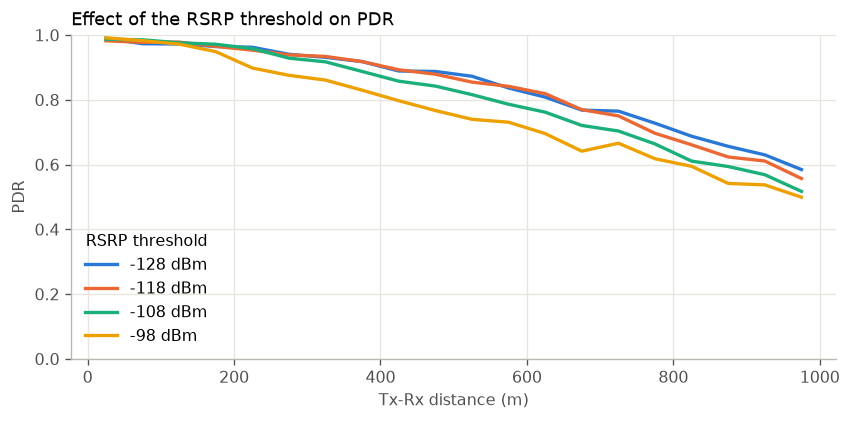

In [5]:
fig, ax = plt.subplots()
colors = dict(zip(sweep, [mr.SERIES_COLORS[0], mr.SERIES_COLORS[1], mr.SERIES_COLORS[2], mr.SERIES_COLORS[3]]))
for threshold, r in sweep.items():
    pdr = mr.pdr_by_distance(r.rx, bin_m=50, max_m=1000)
    ax.plot(pdr.index, pdr.values, label=f"{threshold} dBm", color=colors[threshold])
ax.set_xlabel("Tx-Rx distance (m)")
ax.set_ylabel("PDR")
ax.set_ylim(0, 1)
ax.legend(title="RSRP threshold")
ax.set_title("Effect of the RSRP threshold on PDR")
plt.tight_layout()

**Reading.** From -128 to -108 dBm near-range PDR does not move, but range does: at 550 m, PDR falls from 0.86 to 0.80. At -98 dBm exclusion is too weak: near-range PDR drops to 0.94 and collisions double. So lowering the threshold protects distant receivers.

At -128 dBm the 20 % rule raised the threshold in 17 % of selections, ending at a mean of -125.6 dBm. That is the point of the loop: set too low, the threshold corrects itself. Below about -118 dBm at this load, further lowering mostly reshuffles selections.

In [6]:
modes = {"SPS": sweep[-128], "dynamic": mr.simulate("dynamic", *base, "--Dynamic"),
         "SPS + ReTx": mr.simulate("sps_retx", *base, "--ReTx"),
         "SPS + re-evaluation": mr.simulate("sps_reeval", *base, "--ReEvaluation"),
         "upstream even-UE hack": mr.simulate("legacy", *base, "--LegacyEvenUeOneShot=true")}
pd.DataFrame({name: mr.summary(r) for name, r in modes.items()}).T.round(3)

,PDR near,collision share,CBR,latency p95 [ms],selections,transmissions
SPS,0.967,0.151,0.220,89.1,1208.0,20486.0
dynamic,0.882,0.224,0.206,88.7,20538.0,20483.0
SPS + ReTx,0.987,0.280,0.423,88.5,1227.0,40956.0
SPS + re-evaluation,0.970,0.143,0.219,92.6,1316.0,20484.0
upstream even-UE hack,0.946,0.161,0.219,90.4,10872.0,20481.0


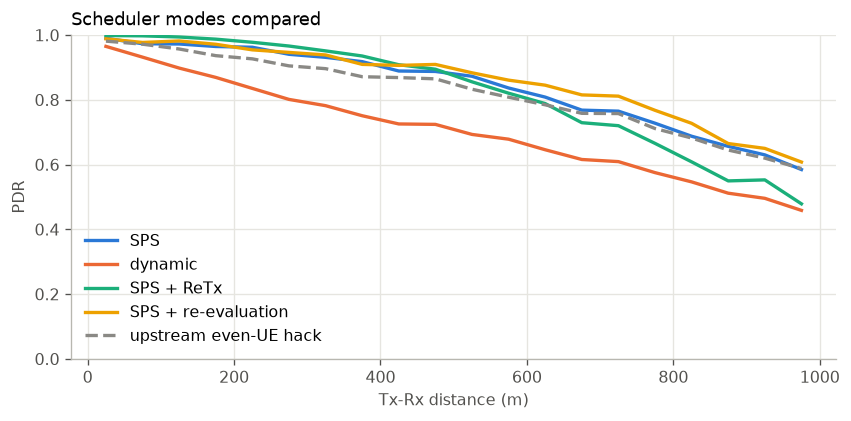

In [7]:
fig, ax = plt.subplots()
styles = {"SPS": (mr.SERIES_COLORS[0], "-"), "dynamic": (mr.SERIES_COLORS[1], "-"), "SPS + ReTx": (mr.SERIES_COLORS[2], "-"),
          "SPS + re-evaluation": (mr.SERIES_COLORS[3], "-"), "upstream even-UE hack": (mr.NEUTRAL, "--")}
for name, r in modes.items():
    pdr = mr.pdr_by_distance(r.rx, bin_m=50, max_m=1000)
    color, style = styles[name]
    ax.plot(pdr.index, pdr.values, label=name, color=color, linestyle=style)
ax.set_xlabel("Tx-Rx distance (m)")
ax.set_ylabel("PDR")
ax.set_ylim(0, 1)
ax.legend()
ax.set_title("Scheduler modes compared")
plt.tight_layout()

**Reading.**
- **Dynamic** is clearly worse: collisions near the sender go from 2.3 % to 10 %, and near PDR from 0.97 to 0.88. Nothing is announced, so nothing is avoided. Median latency improves by only 1 ms.
- **ReTx** gives the best near PDR (0.987) but doubles CBR to 0.42, and from about 500 m on it loses: 0.55 against 0.64 at 900 m. Use it when load allows.
- **Re-evaluation** is the cheap gain: same load and latency, collisions down to 1.8 %, and 0.81 against 0.77 at 700 m.
- **The upstream even-UE hack** nearly doubles collisions, 4.2 % against 2.3 %, with near PDR 0.946 against 0.967, and makes 9 times as many selections. Results published with v4.1 include this effect.

In [8]:
keep = {0.0: sweep[-128]}
keep.update({p: mr.simulate(f"pkeep{int(p * 100)}", *base, f"--pkeep={p}") for p in (0.5, 0.8, 0.95)})
rows = {}
for p, r in keep.items():
    near = r.rx[r.rx.distance < 300]
    rows[p] = {"PDR near": mr.first_copies(near).decoded.mean(), "collisions near": (near.lossType == 3).mean(),
               "counter reselections": int(r.reservations.counterReselections.sum())}
pd.DataFrame(rows).T.rename_axis("Pkeep").round(3)

,PDR near,collisions near,counter reselections
Pkeep,,,
0.00,0.967,0.023,1205.0
0.50,0.960,0.028,668.0
0.80,0.959,0.031,361.0
0.95,0.961,0.028,179.0


**Reading.** `Pkeep` reduces reselections strongly, from 1205 to 179 at 0.95, for a small price in this scenario: near PDR 0.96 against 0.97, and collisions near 2.8 % against 2.3 %. Treat it as one seed on one scenario.

In [9]:
adaptive = {"fixed RRI": sweep[-128], "adaptive": mr.simulate("adaptive", *base, "--AdaptiveRRI"),
            "adaptive, RRI at least 50 ms": mr.simulate("adaptive_min50", *base, "--AdaptiveRRI", "--ns3::NrV2XUeMac::AdaptiveRriMin=50")}
rows = {}
for name, r in adaptive.items():
    near = r.rx[r.rx.distance < 300]
    aoi = mr.age_of_information(r.rx)
    rows[name] = {"PDR near": mr.first_copies(near).decoded.mean(), "collisions near": (near.lossType == 3).mean(), "CBR": r.cbr.cbr.mean(),
                  "transmissions": len(r.tx), "mean RRI": r.tx.RRI.mean(), "AoI (ms)": aoi.aoi.mean(), "peak AoI (ms)": aoi.paoi.mean()}
pd.DataFrame(rows).T.round(3)

,PDR near,collisions near,CBR,transmissions,mean RRI,AoI (ms),peak AoI (ms)
fixed RRI,0.967,0.023,0.220,20486.0,51.014,94.667,132.140
adaptive,0.928,0.057,0.235,23019.0,48.468,68.073,81.114
"adaptive, RRI at least 50 ms",0.986,0.007,0.203,18893.0,58.673,63.841,88.330


**Reading.** The limits decide the outcome.

- **Default limits, `AdaptiveRriMin` 20 ms: worse delivery.** Near PDR drops from 0.97 to 0.93 and collisions rise from 2.3 % to 5.7 %, although AoI improves from 95 to 68 ms. The channel looks free (CBR about 0.2 means a free ratio above 0.5), so every UE keeps speeding up. **This run has not converged:** over 10 s the mean RRI falls from 55 to 40 ms while CBR climbs from 0.17 to 0.26.
- **`AdaptiveRriMin` 50 ms: better on every measure here.** Near PDR 0.986, collisions 0.7 %, AoI 64 ms, with 8 % fewer transmissions. Almost all UEs settle on 60 ms. Uniform RRIs help sensing, since a reservation then predicts the next transmission of each neighbour at the same pace as the UE itself.

Part of that gain comes from the traffic: fixed runs mix 20 ms and 100 ms senders, and adaptive reservation evens them out. Sending a 100 ms application at 60 ms is a higher rate than it asked for, so check that this suits your use case.

With half the fleet adaptive, both halves behave alike, near PDR 0.94 to 0.95 with 4 to 5 % collisions.

One seed and 10 s. Before relying on this, run longer, with several seeds, and at higher load, where the back-off branch finally acts: at this load it never does.

In [10]:
density = {n_: mr.simulate(f"density{n_}", f"--Vehicles={n_}", "--simTime=10", "--mcs=13", "--seed=1", "--Periodic") for n_ in (30, 60, 240)}
density[120] = sweep[-128]
rows = {}
for vehicles in sorted(density):
    r = density[vehicles]
    near = r.rx[r.rx.distance < 300]
    rows[vehicles] = {"vehicles/km": vehicles / 5, "CBR": r.cbr.cbr.mean(), "PDR near": mr.first_copies(near).decoded.mean(),
                      "collisions near": (near.lossType == 3).mean(), "L1 / past Tx": (r.ssps.nCSRfinal / r.ssps.nCSRpastTx).mean(),
                      "raised threshold": (r.ssps.iterations > 1).mean()}
pd.DataFrame(rows).T.rename_axis("vehicles").round(3)

,vehicles/km,CBR,PDR near,collisions near,L1 / past Tx,raised threshold
vehicles,,,,,,
30,6.0,0.045,0.988,0.003,0.793,0.000
60,12.0,0.106,0.982,0.007,0.617,0.008
120,24.0,0.220,0.967,0.023,0.424,0.170
240,48.0,0.400,0.913,0.074,0.281,0.423


**Reading.** Up to 24 vehicles per km the channel stays comfortable. At 48 vehicles per km CBR reaches 0.40 and near PDR drops to 0.91. Note that the 20 ms nodes generate 5 times the packets of the others, so traffic mix matters as much as density.

## 13. Where it differs from 3GPP

| Topic | TS 38.214 / 38.321 | MoReV2X |
|---|---|---|
| RSRP threshold | Table indexed by the priorities of both UEs | One value, `RSRPthreshold`. The packet's PPPP is set but not used |
| L1 target X | 20, 35 or 50 % by priority | Always 20 % |
| Priorities and pre-emption | Supported | None |
| T1 | `0 <= T1 <= T_proc,1` | Fixed 2 slots |
| T2 | `T2min <= T2 <= remaining PDB` | Always the maximum |
| Sensing window | 1100 or 100 ms | 1100 ms |
| Partial sensing | Rel-17 | None |
| HARQ, PSFCH | Feedback for unicast and groupcast | None. Blind re-transmissions only, and PSFCH symbols are only an overhead setting in the AMC |
| Transmissions per TB | Up to 32 | Up to 2 |
| SCI range | Up to 3 resources in 32 slots | 2 |
| Congestion control (CR limit) | Defined by CBR and CR | CBR is measured, and nothing reacts to it. `--AdaptiveRRI` is a separate, non-3GPP scheme |
| Step 2 | UE implementation | Uniform |
| Re-evaluation | T3 before transmission | Yes, with the UMH and all-slots variants |
| Keep probability | `sl-ResourceReselectionProbability` | `Pkeep` |

The README mentions platooning with unicast and groupcast. That code is not in this repository: every UE here broadcasts to one group address.

## 14. Traps

- `--mcs=0` transmits nothing and reports no error: the MAC skips the pool when `m_slGrantMcs` is 0, which is also the default of the attribute.
- `--noIBE` is inverted: the variable is `IBE`, so `--noIBE=false` is what turns in-band emissions off.
- `--Dynamic` UEs announce nothing, so they are invisible to everyone's sensing.
- A new RRI must be added with `PushNewRRIValue`, otherwise an assertion stops a debug build while an optimized build carries on without it.
- `PDB` must not exceed the RRI, and must be below 110 ms.
- The optimized build ignores `NS_ASSERT`. After a change to the MAC, run `tools/debug-check.sh`. It found 2 upstream bugs that the optimized build hid. It now covers 22 modes.
- `ChannelMatrix` is recomputed for all pairs every 100 ms, with LOS drawn again each time. It is O(N^2), which sets the run time at high density. Links change state every 100 ms with no memory.
- RNG streams are not assigned with `AssignStreams`, so changing anything that creates a random variable changes all later draws. Comparing two configurations on the same seed does not pair them.